# Bird Species Classification — COSC 434 Group 12 (simplified version)
Mohamed Alromaithi (`100060448`) · Zayed Alnuaimi (`100061300`)

**The question:** given a photograph of a bird, which of 200 species is it? Dataset: **CUB-200-2011** (`11,788` images, `200` species).

Every model follows the same three steps:

```
photo  ──►  feature vector (a fixed-length list of numbers)  ──►  classifier  ──►  species
```

We compare two ways of producing the feature vector:

| # | Model | Feature vector | Classifier |
|---|---|---|---|
| 1 | `Colour_LR` | colour histogram (512 numbers) | Logistic Regression — the baseline |
| 2 | `ColourLBP_LR` | colour + LBP texture (522 numbers) | Logistic Regression |
| 3 | `ColourLBPGLCM_LR` | colour + LBP texture + GLCM texture (530 numbers) | Logistic Regression |
| 4 | `ColourLBPGLCM_SVM` | colour + LBP texture + GLCM texture (530 numbers) | Linear SVM |
| 5 | `ResNet18_LR` | pretrained ResNet-18, a basic CNN (512 numbers) | Logistic Regression |
| 6 | `EfficientNet_LR` | pretrained EfficientNet-B0, a newer CNN (1,280 numbers) | Logistic Regression |
| 7 | `DINOv2_LR` | pretrained DINOv2, a Vision Transformer (384 numbers) | Logistic Regression |

Each step changes **one** thing:
- 1 → 2 adds the first texture measurement, LBP (same classifier).
- 2 → 3 adds the second texture measurement, the co-occurrence matrix (same classifier).
- 3 → 4 swaps the classifier (same features).
- 3 → 5, 6, 7 swaps hand-made features for a pretrained network's features (same classifier).

## 1. Imports and Settings
Every number that controls the experiment is in the settings cell, with a comment.

In [1]:
# PyTorch is imported first on purpose: on some Macs, importing it after scikit-learn crashes the kernel.
import torch
from torchvision import transforms
from torchvision.models import EfficientNet_B0_Weights, ResNet18_Weights, efficientnet_b0, resnet18

import json
import tarfile
import warnings
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from PIL import Image
from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer, StandardScaler
from sklearn.svm import LinearSVC

In [2]:
SEED = 42                  # Fixes every random choice, so each run gives the same split and models.

PROJECT_FOLDER = Path.cwd()
DATA_FOLDER = PROJECT_FOLDER / 'data' / 'CUB_200_2011'   # the extracted dataset
ARCHIVE_FILE = PROJECT_FOLDER / 'CUB_200_2011.tgz'       # the download, used only if DATA_FOLDER is missing
OUTPUT = PROJECT_FOLDER / 'results_v3_simple'            # every table and figure is saved here
OUTPUT.mkdir(exist_ok=True)

# ---------- Colour and texture features (Section 4) ----------
IMAGE_SIZE = 128           # Every photo is shrunk to 128x128 pixels before measuring.
COLOUR_BINS = 8            # Each of Hue, Saturation, Value is cut into 8 ranges -> 8 x 8 x 8 = 512 numbers.
LBP_POINTS = 8             # LBP texture: compare each pixel with 8 neighbours...
LBP_RADIUS = 1             # ...that sit 1 pixel away                           -> 8 + 2 = 10 numbers.
GLCM_LEVELS = 32           # Co-occurrence texture: reduce grayscale from 256 shades to 32 before counting pairs.
GLCM_DISTANCES = [1, 3]    # Pixel pairs are 1 apart (fine texture) and 3 apart (coarser texture).
GLCM_ANGLES = [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4]   # Pair directions: 0, 45, 90, 135 degrees (in radians).
GLCM_PROPERTIES = ['contrast', 'homogeneity', 'energy', 'correlation']   # 4 summaries x 2 distances = 8 numbers.

# ---------- Classifiers (Section 5) ----------
C_VALUES = [0.01, 0.1, 1.0, 10.0]   # Regularisation strengths to try. Small C = simpler, more cautious model.
MAX_ITERATIONS = 2000               # Upper limit on optimisation steps when fitting a classifier.

# ---------- Pretrained networks (Section 6) ----------
BATCH_SIZE = 32            # Photos pushed through a network at once. Affects speed, not results.
NETWORK_RESIZE = 256       # DINOv2 input: shrink the photo so its short side is 256 pixels...
NETWORK_CROP = 224         # ...then keep the central 224x224 square (the same recipe the two CNNs use).
IMAGENET_MEAN = [0.485, 0.456, 0.406]   # Average R, G, B value over the ImageNet photos (0-1 scale)...
IMAGENET_STD = [0.229, 0.224, 0.225]    # ...and their spread. Used to rescale pixel values for the networks.

# Run the networks on a graphics chip if there is one: 'cuda' = NVIDIA, 'mps' = Apple-silicon Mac.
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
else:
    DEVICE = torch.device('cpu')

torch.manual_seed(SEED)
warnings.simplefilter('error', ConvergenceWarning)   # a classifier that did not finish learning stops the notebook
warnings.filterwarnings('ignore', message='xFormers is not available')   # harmless notice printed by DINOv2
print('Device:', DEVICE, '| Results folder:', OUTPUT.name)

Device: mps | Results folder: results_v3_simple


## 2. Load the Dataset
The dataset is expected in `data/CUB_200_2011/`; if missing, it is extracted from `CUB_200_2011.tgz`. Four small text files describe the images. We join them into one table, `birds`, with one row per image.

In [3]:
if not DATA_FOLDER.is_dir():
    print('Extracting', ARCHIVE_FILE.name, '(takes about a minute)...')
    with tarfile.open(ARCHIVE_FILE) as archive:
        archive.extractall(DATA_FOLDER.parent, filter='data')

def read_table(filename, columns):
    """Read one of the dataset's space-separated text files into a table."""
    return pd.read_csv(DATA_FOLDER / filename, sep=r'\s+', names=columns)

images = read_table('images.txt', ['image_id', 'filename'])                   # where each image is stored
labels = read_table('image_class_labels.txt', ['image_id', 'class_id'])       # its species (1-200): the label
official_split = read_table('train_test_split.txt', ['image_id', 'is_train']) # 1 = training, 0 = test
classes = read_table('classes.txt', ['class_id', 'class_name'])               # the species names

birds = images.merge(labels, on='image_id').merge(official_split, on='image_id').merge(classes, on='class_id')
assert len(birds) == 11788 and birds['class_id'].nunique() == 200             # matches the published numbers
display(birds.head())

,image_id,filename,class_id,is_train,class_name
0,1,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,001.Black_footed_Albatross
1,2,001.Black_footed_Albatross/Black_Footed_Albatr...,1,1,001.Black_footed_Albatross
2,3,001.Black_footed_Albatross/Black_Footed_Albatr...,1,0,001.Black_footed_Albatross
3,4,001.Black_footed_Albatross/Black_Footed_Albatr...,1,1,001.Black_footed_Albatross
4,5,001.Black_footed_Albatross/Black_Footed_Albatr...,1,1,001.Black_footed_Albatross


## 3. Train / Validation / Test Splits

| Split | Images | Job |
|---|---|---|
| **Train** | `4,795` | The classifiers learn from these. |
| **Validation** | `1,199` | Used to choose the setting `C`. The model never learns from them. |
| **Test** | `5,794` | Used once, at the very end, for the reported scores. |

The **test** set is the official CUB test set. The official training set is cut 80 % / 20 % into train and validation. `stratify` makes that cut per species, so every species appears in both parts, and `random_state=SEED` makes it the same cut on every run.

In [4]:
official_train = birds[birds['is_train'] == 1]
test = birds[birds['is_train'] == 0].reset_index(drop=True)

train, validation = train_test_split(official_train, test_size=0.20,
                                     stratify=official_train['class_id'], random_state=SEED)
train = train.sort_values('image_id').reset_index(drop=True)
validation = validation.sort_values('image_id').reset_index(drop=True)

splits = {'train': train, 'validation': validation, 'test': test}
for split_name, table in splits.items():
    table.to_csv(OUTPUT / f'{split_name}.csv', index=False)
    print(f'{split_name}: {len(table)} images, {table["class_id"].nunique()} species')

class_ids = np.sort(birds['class_id'].unique())       # 1, 2, ..., 200
y_train = train['class_id'].to_numpy()                # the correct answers for each split
y_validation = validation['class_id'].to_numpy()
y_test = test['class_id'].to_numpy()

train: 4795 images, 200 species
validation: 1199 images, 200 species
test: 5794 images, 200 species


## 4. Colour and Texture Features
Three small functions turn a photo into numbers: one for colour and two for texture. The first two produce a **histogram**: a count of how many pixels fall into each range of values (each range is a **bin**), ignoring *where* in the photo those pixels are. Dividing by the total turns counts into fractions.

**Colour (512 numbers).** The photo is converted to HSV, which describes each pixel by **H**ue (which colour), **S**aturation (how vivid) and **V**alue (how bright). A bird in sun and in shade keeps roughly the same hue, which makes HSV more stable outdoors than red/green/blue. Each of the three is cut into `8` ranges, and every pixel is counted in one of the `8 × 8 × 8 = 512` combinations.

**LBP texture (10 numbers).** Local Binary Patterns (LBP) work on the grayscale photo. For every pixel, look at its `8` neighbours at distance `1` and note which are brighter than it. The resulting pattern is given a code from 0 to 9: `0` = bright spot, `1`–`7` = edges and corners, `8` = flat area, `9` = irregular speckle. The feature is the histogram of those ten codes, e.g. "40 % flat, 25 % edges…".

**Co-occurrence texture (8 numbers).** LBP looks at one pixel's immediate ring. The Gray-Level Co-occurrence Matrix (GLCM) asks a different question: *when two pixels are a certain distance apart, which pairs of gray shades occur together, and how often?*
- **Building the matrix.** Pick a distance and a direction, say "1 pixel to the right". Go through every pixel, look at its partner, and add 1 to the table cell `[shade of pixel, shade of partner]`. In a smooth image partners have nearly the same shade, so the counts pile up near the table's diagonal; in a busy image they spread far from it.
- **32 shades, not 256.** A 256 × 256 table would be almost empty for a 128 × 128 photo, so shades are first grouped in eights (`256 // 32 = 8`), giving a 32 × 32 table.
- **2 distances × 4 directions = 8 tables.** Distance 1 captures fine detail, distance 3 broader streaks and spots.
- **Each table is summarised by 4 numbers:**

| Property | High when… |
|---|---|
| `contrast` | paired pixels differ a lot in shade (busy, sharp texture) |
| `homogeneity` | paired pixels are nearly equal (smooth) |
| `energy` | a few shade pairs dominate the table (flat or very regular) |
| `correlation` | a pixel's shade predicts its partner's shade (smooth gradients) |

- **Averaged over the 4 directions**, so the result does not depend on which way the bird is facing. That leaves `4 properties × 2 distances = 8` numbers.

Unlike the two histograms, these 8 numbers are not fractions and have very different sizes (contrast can be in the tens, energy around 0.1). Section 5 rescales all features for that reason.

Every photo is first shrunk to `128 × 128` so that extraction is fast and "1 pixel away" means the same thing in every photo.

In [5]:
def load_image(filename):
    """Open one photo as 3-channel colour and shrink it to IMAGE_SIZE x IMAGE_SIZE."""
    with Image.open(DATA_FOLDER / 'images' / filename) as picture:
        return picture.convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)


def colour_histogram(picture):
    """512 numbers: the fraction of pixels in each of the 8 x 8 x 8 Hue/Saturation/Value combinations."""
    pixels = np.asarray(picture.convert('HSV')).reshape(-1, 3)        # one row per pixel: [H, S, V], each 0-255
    counts, _ = np.histogramdd(pixels, bins=(COLOUR_BINS, COLOUR_BINS, COLOUR_BINS), range=[(0, 256)] * 3)
    return counts.ravel() / counts.sum()                              # flatten the 8x8x8 cube, counts -> fractions


def lbp_histogram(picture):
    """10 numbers: the fraction of pixels with each LBP code (0-9)."""
    gray = np.asarray(picture.convert('L'))                           # 'L' = one brightness value per pixel
    codes = local_binary_pattern(gray, P=LBP_POINTS, R=LBP_RADIUS, method='uniform')
    counts = np.bincount(codes.astype(int).ravel(), minlength=LBP_POINTS + 2)   # how often each code 0..9 occurs
    return counts / counts.sum()


def glcm_features(picture):
    """8 numbers: 4 co-occurrence properties at 2 pixel distances, averaged over 4 directions."""
    gray = np.asarray(picture.convert('L'))                           # values 0-255
    reduced = gray // (256 // GLCM_LEVELS)                            # values 0-31: 8 original shades per level
    # symmetric=True counts each pair both ways round; normed=True turns counts into fractions.
    tables = graycomatrix(reduced, distances=GLCM_DISTANCES, angles=GLCM_ANGLES,
                          levels=GLCM_LEVELS, symmetric=True, normed=True)   # shape (32, 32, 2 distances, 4 angles)
    values = []
    for property_name in GLCM_PROPERTIES:
        per_distance_and_angle = graycoprops(tables, property_name)   # shape (2 distances, 4 angles)
        values.append(per_distance_and_angle.mean(axis=1))            # average the angles -> 2 numbers
    return np.concatenate(values)                                     # 4 x 2 = 8 numbers


def extract_colour_and_texture(rows):
    """Run all three functions on every image in `rows`. Returns one table per feature: (images, numbers)."""
    colour, lbp, glcm = [], [], []
    for filename in rows['filename']:
        picture = load_image(filename)
        colour.append(colour_histogram(picture))
        lbp.append(lbp_histogram(picture))
        glcm.append(glcm_features(picture))
    return {'colour': np.array(colour, dtype=np.float32),
            'lbp': np.array(lbp, dtype=np.float32),
            'glcm': np.array(glcm, dtype=np.float32)}

Extraction takes a little while, so results are saved in `results_v3_simple/` and re-loaded on later runs. **Delete the `.npz` files there if you change a feature setting.**

In [6]:
def load_or_extract(cache_file, extract_function, *arguments):
    """Load features saved by an earlier run, or call extract_function(*arguments) now and save the result."""
    if cache_file.is_file():
        return dict(np.load(cache_file))
    print('Extracting features ->', cache_file.name)
    arrays = extract_function(*arguments)
    np.savez_compressed(cache_file, **arrays)
    return arrays


# features['train']['colour'] is the colour table for the training images, and so on.
features = {}
for split_name, rows in splits.items():
    features[split_name] = load_or_extract(OUTPUT / f'colour_texture_{split_name}.npz',
                                           extract_colour_and_texture, rows)

for name in ['colour', 'lbp', 'glcm']:
    print(f'train {name} table: {features["train"][name].shape}')

Extracting features -> colour_texture_train.npz


Extracting features -> colour_texture_validation.npz


Extracting features -> colour_texture_test.npz


train colour table: (4795, 512)
train lbp table: (4795, 10)
train glcm table: (4795, 8)


## 5. Classifiers
Both classifiers are **linear**: for each species they learn one weight per feature, compute a score, and predict the species with the highest score.

- **Logistic Regression** turns the scores into probabilities and learns weights that give the correct species a high probability.
- **Linear SVM** learns, for each species, a boundary separating it from all the others with the widest possible safety margin.

**Preparation (the same for both).** Classifiers work best when all inputs are on a similar scale, so two steps come first:
1. `StandardScaler()` rescales every **column** (feature) to mean 0 and spread 1, so each feature gets an equal say. Without it, a GLCM contrast of 30 would drown out a colour fraction of 0.002 simply for being bigger.
2. `Normalizer()` rescales every **row** (image) to length 1, so no single image with a few extreme values dominates.

`make_pipeline` chains preparation and classifier into one model. The scaler learns its averages from the **training** images only and re-uses them later, so nothing leaks from validation or test images.

**The one setting we tune: `C`.** It controls how closely the classifier fits the training images. Small `C` = simpler, more cautious model; large `C` = fits harder, with more risk of memorising quirks (**overfitting**). We train one model per value in `C_VALUES` and keep the one that scores best on the **validation** images.

**The score: macro-F1.** For each species, F1 combines *precision* (of the images called this species, how many were?) and *recall* (of the images of this species, how many were found?). Macro-F1 is the plain average over the 200 species. For reference, random guessing gives about `1/200 = 0.005`.

In [7]:
def build_logistic_regression(C):
    return make_pipeline(StandardScaler(), Normalizer(),
                         LogisticRegression(C=C, max_iter=MAX_ITERATIONS, random_state=SEED))

def build_linear_svm(C):
    return make_pipeline(StandardScaler(), Normalizer(),
                         LinearSVC(C=C, dual=True, max_iter=MAX_ITERATIONS, random_state=SEED))
    # dual=True picks the solving method that finished reliably on these features; the answer is the same in theory.


def get_features(feature_names, split_name):
    """Place the named feature tables side by side for one split, e.g. 512 colour + 10 LBP = 522 columns."""
    return np.concatenate([features[split_name][name] for name in feature_names], axis=1)

def macro_f1(true_labels, predicted_labels):
    return f1_score(true_labels, predicted_labels, labels=class_ids, average='macro', zero_division=0)


models = {}           # model name -> the trained model with the best C
model_features = {}   # model name -> which feature tables it uses
tuning_rows = []      # one row per (model, C) tried

def tune_model(model_name, build_model, feature_names):
    """Train one model per value of C and keep the one with the best validation macro-F1."""
    X_train = get_features(feature_names, 'train')
    X_validation = get_features(feature_names, 'validation')
    model_features[model_name] = feature_names

    best_score = -1.0
    for C in C_VALUES:
        started = perf_counter()
        model = build_model(C).fit(X_train, y_train)                     # learn from the training images only
        seconds = perf_counter() - started
        score = macro_f1(y_validation, model.predict(X_validation))
        tuning_rows.append({'model': model_name, 'C': C, 'validation_macro_f1': score, 'fit_seconds': seconds})
        if score > best_score:
            best_score, best_C = score, C
            models[model_name] = model
    print(f'{model_name:18s} best C = {best_C:<6} validation macro-F1 = {best_score:.4f}')

In [8]:
tune_model('Colour_LR',         build_logistic_regression, ['colour'])
tune_model('ColourLBP_LR',      build_logistic_regression, ['colour', 'lbp'])
tune_model('ColourLBPGLCM_LR',  build_logistic_regression, ['colour', 'lbp', 'glcm'])
tune_model('ColourLBPGLCM_SVM', build_linear_svm,          ['colour', 'lbp', 'glcm'])

Colour_LR          best C = 1.0    validation macro-F1 = 0.0310


ColourLBP_LR       best C = 10.0   validation macro-F1 = 0.0348


ColourLBPGLCM_LR   best C = 10.0   validation macro-F1 = 0.0358


ColourLBPGLCM_SVM  best C = 0.1    validation macro-F1 = 0.0353


## 6. Pretrained Network Features
In Section 4 **we** decided what to measure. A neural network *learns* what to measure, but that needs millions of photos, so we download networks that others already trained (**pretrained**) and re-use them (**transfer learning**).

| Name | Network | Year | Type | Trained on | Output |
|---|---|---|---|---|---|
| `resnet18` | ResNet-18 | 2015 | CNN | ImageNet: 1.3 million labelled photos | 512 numbers |
| `efficientnet` | EfficientNet-B0 | 2019 | CNN | ImageNet: 1.3 million labelled photos | 1,280 numbers |
| `dinov2` | DINOv2 ViT-S/14 | 2023 | Vision Transformer | 142 million photos, no labels | 384 numbers |

- A **CNN** slides small filters over the image; early layers detect edges and colours, later layers whole parts such as beaks and wings. A **Vision Transformer** cuts the image into small patches and lets every patch compare itself with every other patch.
- **Feature extractor:** the two CNNs end in a layer that outputs 1,000 ImageNet category scores. We replace it with `torch.nn.Identity()` ("pass through unchanged"), so the network outputs the numbers it computed just before: a feature vector, playing the same role as our histograms. DINOv2 already outputs a feature vector.
- **Frozen:** the networks' weights are never changed. Only the Logistic Regression on top is trained, exactly as in Section 5.
- **Preprocessing:** a pretrained network needs images prepared the way it was trained: short side resized to 256, central `224 × 224` square, colour values rescaled with the ImageNet averages. The CNNs supply these steps via `weights.transforms()`; for DINOv2 we write the same steps ourselves.

The first run downloads the pretrained weights (about 150 MB in total) and DINOv2's model code from its official GitHub repository.

In [9]:
def load_resnet18():
    weights = ResNet18_Weights.IMAGENET1K_V1
    network = resnet18(weights=weights)
    network.fc = torch.nn.Identity()               # remove the final 1,000-category layer (called 'fc' here)
    return network, weights.transforms()

def load_efficientnet():
    weights = EfficientNet_B0_Weights.IMAGENET1K_V1
    network = efficientnet_b0(weights=weights)
    network.classifier = torch.nn.Identity()       # same idea; the final layer has a different name
    return network, weights.transforms()

def load_dinov2():
    network = torch.hub.load('facebookresearch/dinov2', 'dinov2_vits14', trust_repo=True, verbose=False)
    preprocess = transforms.Compose([              # a list of steps applied in order
        transforms.Resize(NETWORK_RESIZE, interpolation=transforms.InterpolationMode.BICUBIC),
        transforms.CenterCrop(NETWORK_CROP),
        transforms.ToTensor(),                     # image -> numbers between 0 and 1
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])
    return network, preprocess


def extract_network_features(rows, network, preprocess):
    """Push every image in `rows` through a frozen network. Returns one feature vector per image."""
    filenames = rows['filename'].tolist()
    outputs = []
    with torch.inference_mode():                                       # no training bookkeeping: faster
        for start in range(0, len(filenames), BATCH_SIZE):
            batch = []
            for filename in filenames[start:start + BATCH_SIZE]:
                with Image.open(DATA_FOLDER / 'images' / filename) as picture:
                    batch.append(preprocess(picture.convert('RGB')))   # shape (3, 224, 224)
            batch = torch.stack(batch).to(DEVICE)                      # shape (batch, 3, 224, 224)
            outputs.append(network(batch).cpu().numpy())               # shape (batch, output length)
    return {'features': np.concatenate(outputs).astype(np.float32)}


for network_name, load_network in [('resnet18', load_resnet18), ('efficientnet', load_efficientnet), ('dinov2', load_dinov2)]:
    network, preprocess = load_network()
    network.requires_grad_(False)          # freeze: no weight is ever updated
    network.eval().to(DEVICE)              # prediction mode, on the chosen device
    for split_name, rows in splits.items():
        result = load_or_extract(OUTPUT / f'{network_name}_{split_name}.npz',
                                 extract_network_features, rows, network, preprocess)
        features[split_name][network_name] = result['features']
    print(f'train {network_name} table: {features["train"][network_name].shape}')

train resnet18 table: (4795, 512)


train efficientnet table: (4795, 1280)


train dinov2 table: (4795, 384)


In [10]:
# Same classifier and same tuning as Section 5; only the features change.
tune_model('ResNet18_LR',     build_logistic_regression, ['resnet18'])
tune_model('EfficientNet_LR', build_logistic_regression, ['efficientnet'])
tune_model('DINOv2_LR',       build_logistic_regression, ['dinov2'])

pd.DataFrame(tuning_rows).to_csv(OUTPUT / 'validation_trials.csv', index=False)

ResNet18_LR        best C = 10.0   validation macro-F1 = 0.6219


EfficientNet_LR    best C = 10.0   validation macro-F1 = 0.7416


DINOv2_LR          best C = 10.0   validation macro-F1 = 0.8693


## 7. Final Test Evaluation
All seven models and their `C` values were chosen using validation images only. Each now predicts the `5,794` test images, which nothing so far has touched. **Accuracy** is the fraction of test images given the correct species; **macro-F1** is as defined in Section 5. Random guessing scores about `0.005`.

,accuracy,macro_f1
model,,
Colour_LR,0.0340,0.0272
ColourLBP_LR,0.0421,0.0402
ColourLBPGLCM_LR,0.0469,0.0450
ColourLBPGLCM_SVM,0.0450,0.0380
ResNet18_LR,0.6288,0.6299
EfficientNet_LR,0.7730,0.7737
DINOv2_LR,0.8799,0.8788


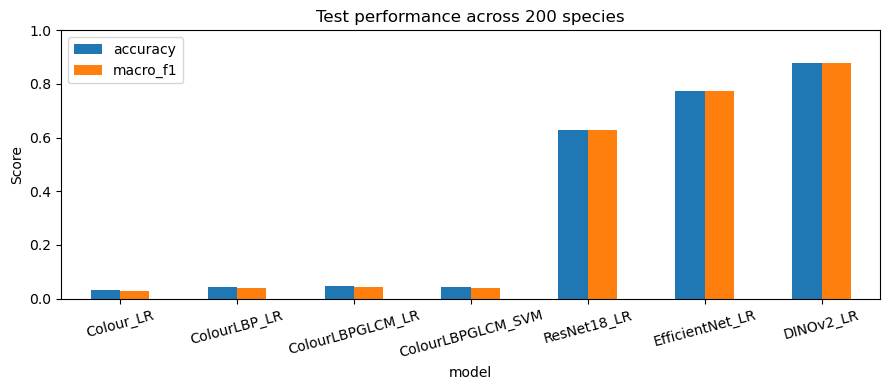

In [11]:
predictions = test[['image_id', 'class_id']].copy()
result_rows = []
for model_name, model in models.items():
    predicted = model.predict(get_features(model_features[model_name], 'test'))
    predictions[model_name] = predicted
    result_rows.append({'model': model_name,
                        'accuracy': accuracy_score(y_test, predicted),
                        'macro_f1': macro_f1(y_test, predicted)})

results = pd.DataFrame(result_rows).set_index('model')
results.to_csv(OUTPUT / 'test_metrics.csv')
predictions.to_csv(OUTPUT / 'test_predictions.csv', index=False)
display(results.round(4))

ax = results.plot.bar(figsize=(9, 4), ylim=(0, 1), rot=15)
ax.set_title(f'Test performance across {len(class_ids)} species')
ax.set_ylabel('Score')
plt.tight_layout()
plt.savefig(OUTPUT / 'model_comparison.png', dpi=150)
plt.show()

## 8. Error Analysis
A **confusion matrix** is a 200 × 200 table: cell `[row, column]` counts the test images whose true species is `row` and whose predicted species is `column`. The diagonal holds correct answers; everything else is a mistake. For the conventional model that uses every hand-made feature and for the best network we list the ten largest mistakes: which species is taken for which, most often.

**What the tables below show:**
- **`ColourLBPGLCM_LR`** mixes up birds that share an overall colour palette, whether or not they look alike in shape: *Pine Grosbeak* → *Purple Finch* (7, both rosy red), *Blue Grosbeak* → *Painted Bunting* (6, both blue), *Cardinal* → *Summer Tanager* (5, both red).
- **`DINOv2_LR`** makes the mistakes a birdwatcher would make, between near-identical relatives: *Great Grey Shrike* ↔ *Loggerhead Shrike* (10 each way), *Long-tailed Jaeger* → *Pomarine Jaeger* (9), *Common Tern* → *Arctic Tern* (9).

In [12]:
def bird_name(class_id):
    """'001.Black_footed_Albatross' -> 'Black footed Albatross'."""
    folder_name = classes.set_index('class_id').loc[class_id, 'class_name']
    return folder_name.split('.', 1)[1].replace('_', ' ')


def most_confused_pairs(model_name, how_many=10):
    """The largest off-diagonal cells of a model's confusion matrix."""
    mistakes = confusion_matrix(y_test, predictions[model_name], labels=class_ids)
    np.fill_diagonal(mistakes, 0)                                       # the diagonal is correct answers: ignore it
    largest_first = np.argsort(mistakes, axis=None)[::-1][:how_many]    # positions in the flattened table
    true_positions, predicted_positions = np.unravel_index(largest_first, mistakes.shape)
    return pd.DataFrame({'model': model_name,
                         'true_species': [bird_name(class_ids[i]) for i in true_positions],
                         'predicted_species': [bird_name(class_ids[i]) for i in predicted_positions],
                         'count': mistakes[true_positions, predicted_positions]})


top_pairs = pd.concat([most_confused_pairs(model_name) for model_name in models])
top_pairs.to_csv(OUTPUT / 'top_confusion_pairs.csv', index=False)
for model_name in ['ColourLBPGLCM_LR', 'DINOv2_LR']:
    display(top_pairs[top_pairs['model'] == model_name])

,model,true_species,predicted_species,count
0,ColourLBPGLCM_LR,Pine Grosbeak,Purple Finch,7
1,ColourLBPGLCM_LR,Blue Grosbeak,Painted Bunting,6
2,ColourLBPGLCM_LR,Cardinal,Summer Tanager,5
3,ColourLBPGLCM_LR,Florida Jay,Blue Grosbeak,5
4,ColourLBPGLCM_LR,Gray Kingbird,Pomarine Jaeger,4
5,ColourLBPGLCM_LR,Pigeon Guillemot,Horned Puffin,4
6,ColourLBPGLCM_LR,Pacific Loon,Red breasted Merganser,4
7,ColourLBPGLCM_LR,Ruby throated Hummingbird,Anna Hummingbird,4
8,ColourLBPGLCM_LR,Nelson Sharp tailed Sparrow,Le Conte Sparrow,4
9,ColourLBPGLCM_LR,Red breasted Merganser,Black footed Albatross,4


,model,true_species,predicted_species,count
0,DINOv2_LR,Great Grey Shrike,Loggerhead Shrike,10
1,DINOv2_LR,Loggerhead Shrike,Great Grey Shrike,10
2,DINOv2_LR,Long tailed Jaeger,Pomarine Jaeger,9
3,DINOv2_LR,Common Tern,Artic Tern,9
4,DINOv2_LR,Least Flycatcher,Acadian Flycatcher,9
5,DINOv2_LR,Brandt Cormorant,Pelagic Cormorant,8
6,DINOv2_LR,Forsters Tern,Common Tern,8
7,DINOv2_LR,Fish Crow,American Crow,8
8,DINOv2_LR,Chuck will Widow,Whip poor Will,8
9,DINOv2_LR,House Sparrow,Field Sparrow,7


## 9. Summary
**Results on the `5,794` test images (`200` species, random guessing ≈ `0.005`):**

| Model | Test accuracy | Test macro-F1 |
|---|---|---|
| `Colour_LR` (baseline) | `3.40 %` | `0.0272` |
| `ColourLBP_LR` | `4.21 %` | `0.0402` |
| `ColourLBPGLCM_LR` | `4.69 %` | `0.0450` |
| `ColourLBPGLCM_SVM` | `4.50 %` | `0.0380` |
| `ResNet18_LR` | `62.88 %` | `0.6299` |
| `EfficientNet_LR` | `77.30 %` | `0.7737` |
| `DINOv2_LR` | `87.99 %` | `0.8788` |

- **Each texture measurement helps a little:** with the same classifier, macro-F1 rises from `0.0272` (colour) to `0.0402` (+ LBP) to `0.0450` (+ co-occurrence). The 8 co-occurrence numbers add less than the 10 LBP numbers did.
- **The choice of classifier barely matters:** on the same 530 features, Logistic Regression and the Linear SVM score within `0.007` of each other on test and within `0.001` on validation, so neither can be called better.
- **The features matter enormously:** with the same Logistic Regression, swapping hand-made features for a pretrained network's features lifts accuracy from about `5 %` to `63 %`–`88 %`.
- **Why:** species differ in small, localised details (an eye ring, a wing bar, a beak shape). Whole-photo colour and texture statistics discard position and shape and measure the background along with the bird. A pretrained network describes parts and shapes. The error analysis agrees: the conventional model confuses birds with similar overall colours, the network confuses close relatives.
- **Newer networks give better features:** `62.9 %` → `77.3 %` → `88.0 %` with identical classifier and training photos.

**Limitations:**
- Colour and texture are measured over the whole photo, background included; the dataset's bounding boxes are not used.
- All scores come from one split with one seed, so small differences (such as between the two classifiers, or the gain from the co-occurrence features) are not reliable.
- Most of the Logistic Regression models, including all three on network features, chose `C = 10`, the largest value tried, so a wider range of `C` might do slightly better.
- DINOv2 differs from the CNNs in network type, training data and training method at once, so its lead cannot be credited to any one of those.
- The pretrained networks may have seen some CUB photographs during their own training, which could flatter their scores.

In [13]:
settings = {
    'seed': SEED, 'C_values': C_VALUES, 'max_iterations': MAX_ITERATIONS,
    'split_sizes': [len(train), len(validation), len(test)],
    'image_size': IMAGE_SIZE, 'colour_bins': COLOUR_BINS, 'lbp_points': LBP_POINTS, 'lbp_radius': LBP_RADIUS,
    'glcm_levels': GLCM_LEVELS, 'glcm_distances': GLCM_DISTANCES, 'glcm_properties': GLCM_PROPERTIES,
    'network_resize': NETWORK_RESIZE, 'network_crop': NETWORK_CROP, 'device': str(DEVICE),
    'pretrained_networks': ['torchvision ResNet18 IMAGENET1K_V1', 'torchvision EfficientNet_B0 IMAGENET1K_V1',
                            'torch.hub facebookresearch/dinov2 dinov2_vits14'],
    'versions': {package: version(package) for package in
                 ['numpy', 'pandas', 'Pillow', 'scikit-learn', 'scikit-image', 'torch', 'torchvision']},
}
(OUTPUT / 'settings.json').write_text(json.dumps(settings, indent=2))
display(pd.DataFrame(tuning_rows).groupby('model', sort=False)['fit_seconds'].sum().rename('total_tuning_seconds').round(1))

model
Colour_LR             2.1
ColourLBP_LR          2.0
ColourLBPGLCM_LR      2.3
ColourLBPGLCM_SVM    38.2
ResNet18_LR           1.8
EfficientNet_LR       3.5
DINOv2_LR             1.9
Name: total_tuning_seconds, dtype: float64